## Probability, Logistic Regression, and Calibration

### Learning Goals
* Understand how logistic regression transforms linear decision scores into probability estimates using the sigmoid function $\sigma(z)$.
* Evaluate binary classification performance across varying decision thresholds using Accuracy, Precision, Recall, and ROC-AUC.
* Recognize the impact of class imbalance and the fundamental distinction between classification accuracy and probability calibration.

---

### 1. From a Score to a Probability

Logistic regression maps an unconstrained linear combination of inputs $z = w^T x + b$ into a valid probability $P(Y=1 \mid x) \in (0, 1)$ via the sigmoid (logistic) function:
$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

While the function guarantees outputs strictly between $0$ and $1$, the resulting score is only reliable as a true probability estimate if the model is well-calibrated.

<>:11: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:15: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:11: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:15: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
/tmp/ipykernel_4232/938178470.py:11: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  plt.plot(z, p, color='darkcyan', linewidth=2, label="$\sigma(z) = \\frac{1}{1 + e^{-z}}$")
/tmp/ipykernel_4232/938178470.py:15: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will

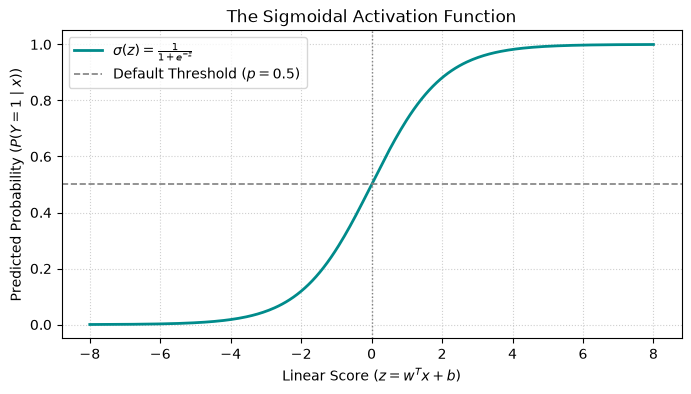

Sample Linear Score to Probability Mappings:
  Score z = -3  ->  p = 0.047
  Score z = -1  ->  p = 0.269
  Score z =  0  ->  p = 0.500
  Score z =  1  ->  p = 0.731
  Score z =  3  ->  p = 0.953


In [1]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

z = np.linspace(-8, 8, 300)
p = sigmoid(z)

plt.figure(figsize=(8, 4))
plt.plot(z, p, color='darkcyan', linewidth=2, label="$\sigma(z) = \\frac{1}{1 + e^{-z}}$")
plt.axhline(0.5, color='gray', linestyle="--", linewidth=1.2, label="Default Threshold ($p=0.5$)")
plt.axvline(0.0, color='gray', linestyle=":", linewidth=1.0)
plt.xlabel("Linear Score ($z = w^T x + b$)")
plt.ylabel("Predicted Probability ($P(Y=1 \mid x)$)")
plt.title("The Sigmoidal Activation Function")
plt.legend()
plt.grid(linestyle=':', alpha=0.6)
plt.show()

print("Sample Linear Score to Probability Mappings:")
for score in [-3, -1, 0, 1, 3]:
    print(f"  Score z = {score:>2}  ->  p = {sigmoid(score):.3f}")

### 2. Training and Evaluating a Classifier

A classification decision threshold converts continuous probabilities into binary discrete class predictions $\hat{y} \in \{0, 1\}$. 

While $0.5$ is standard, tuning the threshold is vital when evaluating imbalanced datasets or asymmetric false-positive vs. false-negative error costs.

In [2]:
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

X, y = make_classification(
    n_samples=1200,
    n_features=8,
    n_informative=5,
    n_redundant=1,
    weights=[0.8, 0.2],  # Imbalanced 80/20 class distribution
    random_state=42,
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

probabilities = model.predict_proba(X_test)[:, 1]

print("Threshold Evaluation Matrix:")
for threshold in [0.3, 0.5, 0.7]:
    predictions = (probabilities >= threshold).astype(int)
    acc = accuracy_score(y_test, predictions)
    prec = precision_score(y_test, predictions, zero_division=0)
    rec = recall_score(y_test, predictions, zero_division=0)
    print(f"  Threshold = {threshold:.1f} | Accuracy = {acc:.3f} | Precision = {prec:.3f} | Recall = {rec:.3f}")

print(f"\nOverall ROC-AUC Score: {roc_auc_score(y_test, probabilities):.3f}")

Threshold Evaluation Matrix:
  Threshold = 0.3 | Accuracy = 0.853 | Precision = 0.614 | Recall = 0.717
  Threshold = 0.5 | Accuracy = 0.863 | Precision = 0.828 | Recall = 0.400
  Threshold = 0.7 | Accuracy = 0.840 | Precision = 0.929 | Recall = 0.217

Overall ROC-AUC Score: 0.856


---

### Exercises

Try each problem before running the verification code below:

1. Why can standard classification accuracy be misleading when evaluating imbalanced datasets?
2. What happens to recall and precision when the classification decision threshold is raised from $0.3$ to $0.7$?
3. Why is probability calibration fundamentally distinct from classification accuracy?

In [3]:
# --- Exercise Verification & Explanations ---
print("=== Exercise Solutions & Checks ===")

print("\n1. Why Accuracy is Misleading for Imbalanced Data:")
print("   - On an 80/20 imbalanced dataset, a trivial model predicting 100% negative class")
print("     achieves 80% accuracy while failing to identify a single positive case (0% recall).")

print("\n2. Raising the Classification Threshold:")
print("   - Raising the threshold requires stronger evidence to predict the positive class,")
print("     which reduces false positives (increasing precision) but increases false negatives (reducing recall).")

print("\n3. Calibration vs. Accuracy:")
print("   - Accuracy checks whether predictions exceed a decision boundary. Calibration checks whether")
print("     a predicted probability of 70% corresponds to an actual 70% event occurrence rate in practice.")

=== Exercise Solutions & Checks ===

1. Why Accuracy is Misleading for Imbalanced Data:
   - On an 80/20 imbalanced dataset, a trivial model predicting 100% negative class
     achieves 80% accuracy while failing to identify a single positive case (0% recall).

2. Raising the Classification Threshold:
   - Raising the threshold requires stronger evidence to predict the positive class,
     which reduces false positives (increasing precision) but increases false negatives (reducing recall).

3. Calibration vs. Accuracy:
   - Accuracy checks whether predictions exceed a decision boundary. Calibration checks whether
     a predicted probability of 70% corresponds to an actual 70% event occurrence rate in practice.
